# Task 1: Dataset Exploration and Understanding

This section loads and explores the dataset, examines the eight image classes, checks image quality and data integrity, and prepares the training and validation split.

In [2]:
import pandas as pd

labels = pd.read_csv("../train_labels.csv")

print("Dataset shape:", labels.shape)
display(labels.head())

Dataset shape: (63660, 2)


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogFace
3,4,DogNose
4,5,DogNose


In [2]:
%pip install pandas


     ---------------------------------------- 11.4/11.4 MB 1.5 MB/s eta 0:00:00
     -------------------------------------- 15.9/15.9 MB 147.9 kB/s eta 0:00:00
     ------------------------------------ 506.3/506.3 KB 214.6 kB/s eta 0:00:00
     ------------------------------------ 348.0/348.0 KB 218.5 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
You should consider upgrading via the 'c:\Users\simon\AppData\Local\Python\pythoncore-3.9-64\python.exe -m pip install --upgrade pip' command.


In [3]:
# Count the number of images in each class
class_counts = labels["class"].value_counts()

print("Number of images per class:")
print(class_counts)

# Check the total number of classes
print("\nTotal classes:", labels["class"].nunique())

Number of images per class:
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogNose      5790
DogMouth     5790
DogFace      5790
Name: count, dtype: int64

Total classes: 8


In [3]:
%pip install matplotlib

     ---------------------------------------- 7.8/7.8 MB 6.4 MB/s eta 0:00:00
     ---------------------------------------- 1.5/1.5 MB 7.0 MB/s eta 0:00:00
     ---------------------------------------- 55.8/55.8 KB 2.9 MB/s eta 0:00:00
     ---------------------------------------- 7.0/7.0 MB 7.6 MB/s eta 0:00:00
     -------------------------------------- 126.4/126.4 KB 7.3 MB/s eta 0:00:00
     ------------------------------------- 211.8/211.8 KB 13.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
You should consider upgrading via the 'c:\Users\simon\AppData\Local\Python\pythoncore-3.9-64\python.exe -m pip install --upgrade pip' command.


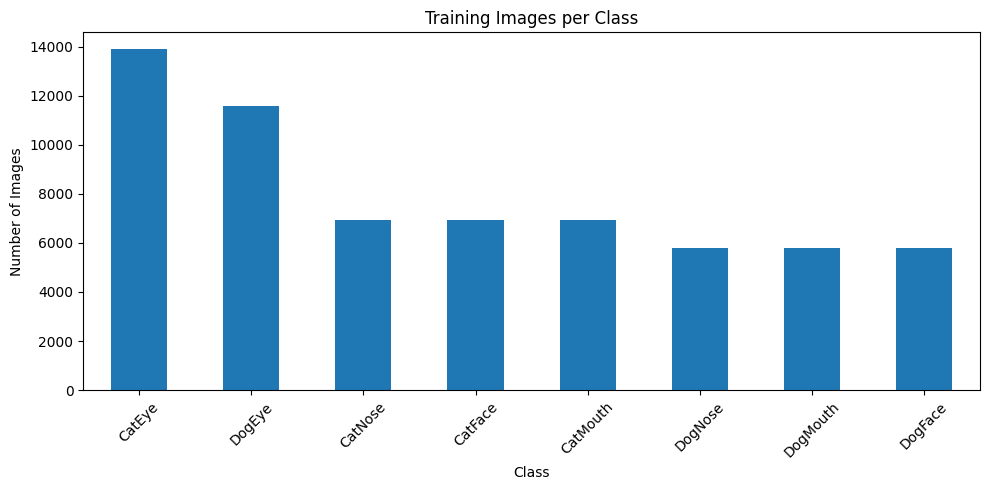

In [4]:
import matplotlib.pyplot as plt

# Plot the number of images in each class
class_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Training Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
# Check for missing values
print("Missing values:")
print(labels.isnull().sum())

# Check for duplicate image IDs
print("\nDuplicate image IDs:")
print(labels["image_id"].duplicated().sum())

# Check total records
print("\nTotal training records:", len(labels))

Missing values:
image_id    0
class       0
dtype: int64

Duplicate image IDs:
0

Total training records: 63660


In [6]:
from pathlib import Path

# Find the training image folder
train_folder = Path("../train/train")

# Check whether the folder exists
print("Folder exists:", train_folder.exists())

# Count JPG images
print("Number of image files:", len(list(train_folder.glob("*.jpg"))))

Folder exists: True
Number of image files: 63660


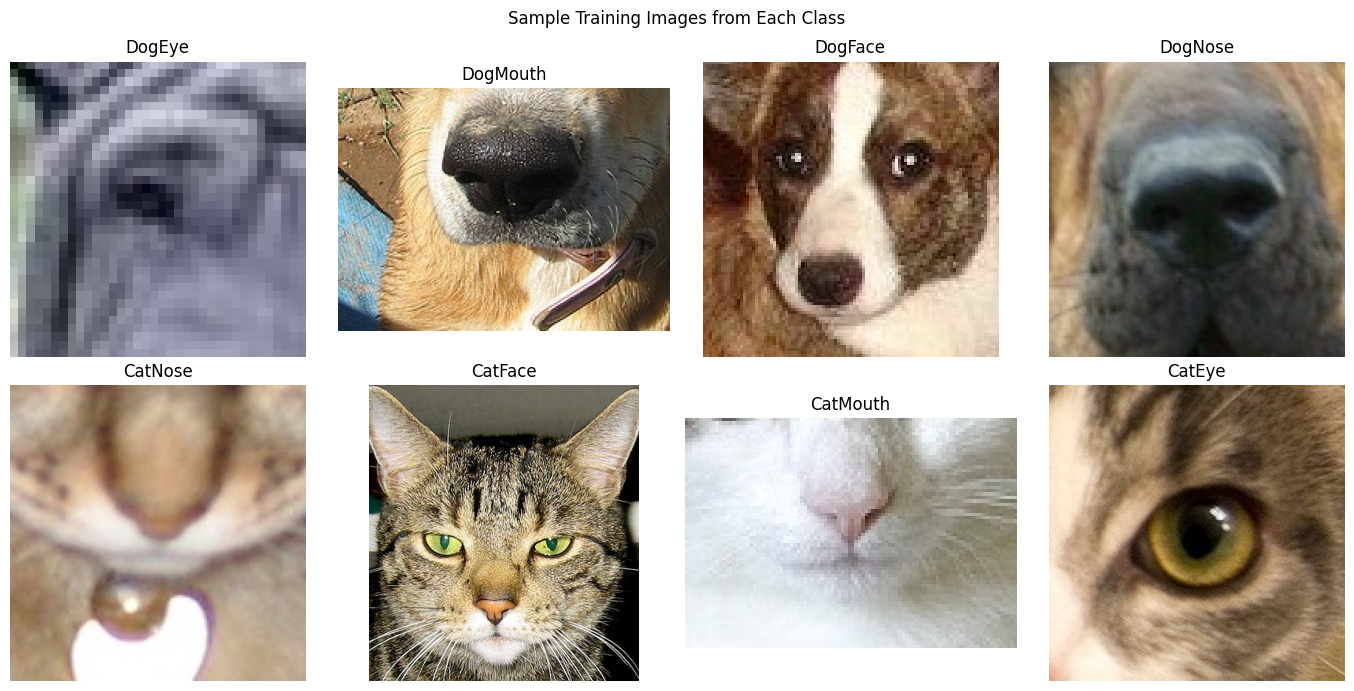

In [7]:
from PIL import Image
import matplotlib.pyplot as plt

# Get the eight different classes
classes = labels["class"].unique()

# Create a grid with 2 rows and 4 columns
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, class_name in zip(axes.flat, classes):

    # Select one image from each class
    sample = labels[labels["class"] == class_name].iloc[0]

    # Find the image using its ID
    image_id = int(sample["image_id"])
    image_path = train_folder / f"{image_id:05d}.jpg"

    # Open and display the image
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Sample Training Images from Each Class")
plt.tight_layout()
plt.show()

In [8]:
%pip install pillow

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\simon\AppData\Local\Python\pythoncore-3.9-64\python.exe -m pip install --upgrade pip' command.


In [9]:
from PIL import Image
from collections import Counter

image_sizes = []
corrupted_images = []

# Check every training image
for image_path in train_folder.glob("*.jpg"):
    try:
        with Image.open(image_path) as img:
            img.load()
            image_sizes.append(img.size)
    except Exception:
        corrupted_images.append(image_path.name)

# Count the different image dimensions
size_counts = Counter(image_sizes)

print("Total images checked:", len(image_sizes) + len(corrupted_images))
print("Different image dimensions:", len(size_counts))
print("Most common image sizes:", size_counts.most_common(10))
print("Corrupted images:", len(corrupted_images))
print("Examples of corrupted files:", corrupted_images[:10])


Total images checked: 63660
Different image dimensions: 7861
Most common image sizes: [((40, 40), 1062), ((48, 48), 1051), ((42, 42), 1050), ((38, 38), 1002), ((44, 44), 1002), ((46, 46), 985), ((34, 34), 978), ((36, 36), 963), ((54, 54), 952), ((52, 52), 928)]
Corrupted images: 0
Examples of corrupted files: []


In [10]:
# Get all image IDs from the CSV
label_ids = set(labels["image_id"].astype(int))

# Get all image IDs from the JPG filenames
file_ids = {
    int(path.stem)
    for path in train_folder.glob("*.jpg")
}

# Compare the image IDs
missing_images = label_ids - file_ids
unlabelled_images = file_ids - label_ids

print("Images missing from folder:", len(missing_images))
print("Images without labels:", len(unlabelled_images))
print("Matching image IDs:", len(label_ids & file_ids))

Images missing from folder: 0
Images without labels: 0
Matching image IDs: 63660


In [11]:
from pathlib import Path

# Locate the test images
test_folder = Path("../test")

# Find all JPG files, including subfolders
test_images = list(test_folder.rglob("*.jpg"))

print("Test folder exists:", test_folder.exists())
print("Number of test images:", len(test_images))
print("First five test images:")

for image in test_images[:5]:
    print(image)

Test folder exists: True
Number of test images: 29443
First five test images:
..\test\test\00001.jpg
..\test\test\00002.jpg
..\test\test\00003.jpg
..\test\test\00004.jpg
..\test\test\00005.jpg


In [12]:
# Load the Kaggle submission template
submission = pd.read_csv("../sample_submission.csv")

print("Submission shape:", submission.shape)
print("\nColumn names:", submission.columns.tolist())
print("\nFirst five rows:")
display(submission.head())

# Compare submission IDs with test image filenames
submission_ids = set(submission["image_id"].astype(int))
test_ids = {int(path.stem) for path in test_images}

print("\nTest images missing from submission:",
      len(test_ids - submission_ids))

print("Submission IDs without test images:",
      len(submission_ids - test_ids))

Submission shape: (29443, 2)

Column names: ['image_id', 'class']

First five rows:


,image_id,class
0,1,DogEye
1,2,CatNose
2,3,CatNose
3,4,DogFace
4,5,DogMouth



Test images missing from submission: 0
Submission IDs without test images: 0


In [13]:
from pathlib import Path

test_folder = Path("../test")

print("Folders inside test:")
for folder in test_folder.iterdir():
    print(folder.name, "Folder" if folder.is_dir() else "File")

print("\nTotal JPG images:",
      len(list(test_folder.rglob("*.jpg"))))

print("\nTotal files:",
      len([p for p in test_folder.rglob("*") if p.is_file()]))

Folders inside test:
Assessment3.ipynb File
Assessment3_backup.ipynb File
baseline_results.csv File
best_mobilenetv3.pth File
best_mobilenetv3_finetuned.pth File
kaggle_results.csv File
model_comparison.csv File
submission.csv File
submission_finetuned.csv File
test Folder

Total JPG images: 29443

Total files: 29452


In [14]:
from pathlib import Path

test_images = list(Path("../test/test").glob("*.jpg"))

print("Total test images:", len(test_images))

Total test images: 29443


In [15]:
submission_ids = set(submission["image_id"].astype(int))
test_ids = {int(path.stem) for path in test_images}

print("Missing test images:", len(submission_ids - test_ids))
print("Extra test images:", len(test_ids - submission_ids))
print("Matching IDs:", len(submission_ids & test_ids))

Missing test images: 0
Extra test images: 0
Matching IDs: 29443


In [16]:
# Compare training image IDs with CSV labels
label_ids = set(labels["image_id"].astype(int))

train_ids = {
    int(path.stem)
    for path in train_folder.glob("*.jpg")
}

print("Missing training images:", len(label_ids - train_ids))
print("Images without labels:", len(train_ids - label_ids))
print("Matching training IDs:", len(label_ids & train_ids))

Missing training images: 0
Images without labels: 0
Matching training IDs: 63660


In [17]:
# Analyse training image dimensions
widths = [size[0] for size in image_sizes]
heights = [size[1] for size in image_sizes]

print("Smallest width:", min(widths))
print("Largest width:", max(widths))

print("Smallest height:", min(heights))
print("Largest height:", max(heights))

# Count images smaller than 32x32 pixels
small_images = sum(
    w < 32 or h < 32
    for w, h in image_sizes
)

print("Images with width or height below 32 pixels:", small_images)

Smallest width: 4
Largest width: 2219
Smallest height: 4
Largest height: 2219
Images with width or height below 32 pixels: 4130


In [18]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\simon\AppData\Local\Python\pythoncore-3.9-64\python.exe -m pip install --upgrade pip' command.


In [19]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels["class"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nValidation class distribution:")
print(val_df["class"].value_counts())

print("\nOverlapping image IDs:",
      len(set(train_df["image_id"]) & set(val_df["image_id"])))

Training samples: 50928
Validation samples: 12732

Training class distribution:
class
CatEye      11107
DogEye       9264
CatMouth     5554
CatFace      5554
CatNose      5553
DogFace      4632
DogNose      4632
DogMouth     4632
Name: count, dtype: int64

Validation class distribution:
class
CatEye      2777
DogEye      2316
CatNose     1389
CatFace     1388
CatMouth    1388
DogMouth    1158
DogFace     1158
DogNose     1158
Name: count, dtype: int64

Overlapping image IDs: 0


In [20]:
label_ids = set(labels["image_id"].astype(int))
train_ids = {
    int(path.stem)
    for path in train_folder.glob("*.jpg")
}

print("Missing training images:", len(label_ids - train_ids))
print("Images without labels:", len(train_ids - label_ids))
print("Matching training IDs:", len(label_ids & train_ids))

Missing training images: 0
Images without labels: 0
Matching training IDs: 63660


# Task 2: Data Preprocessing and Pipeline Preparation

This section prepares the image data for deep learning, including label encoding, image resizing, normalisation, augmentation, and data loading.

In [21]:


try:
    import torch
    import torchvision

    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("GPU available:", torch.cuda.is_available())

except ImportError as e:
    print("Missing library:", e)

PyTorch version: 2.5.1+cpu
Torchvision version: 0.20.1+cpu
GPU available: False


In [22]:
%pip install "torch==2.5.1" "torchvision==0.20.1"

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\simon\AppData\Local\Python\pythoncore-3.9-64\python.exe -m pip install --upgrade pip' command.


In [23]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.5.1+cpu
Torchvision version: 0.20.1+cpu
GPU available: False


In [24]:
# Task 2 - Encode class labels

# Define a consistent alphabetical order
class_names = sorted(labels["class"].unique())

# Create mappings between names and numbers
class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

# Add numerical labels to training and validation sets
train_df = train_df.copy()
val_df = val_df.copy()

train_df["label"] = train_df["class"].map(class_to_idx)
val_df["label"] = val_df["class"].map(class_to_idx)

print("Class mappings:")
for name, idx in class_to_idx.items():
    print(f"{idx}: {name}")

print("\nTraining samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Missing encoded labels:",
      train_df["label"].isna().sum() + val_df["label"].isna().sum())

Class mappings:
0: CatEye
1: CatFace
2: CatMouth
3: CatNose
4: DogEye
5: DogFace
6: DogMouth
7: DogNose

Training samples: 50928
Validation samples: 12732
Missing encoded labels: 0


In [25]:
# Task 2 - Image preprocessing and augmentation

from torchvision import transforms

IMAGE_SIZE = 128

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation transformations
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations:")
print(train_transform)

print("\nValidation transformations:")
print(val_transform)

Training transformations:
Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transformations:
Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [26]:
# Task 2 - Create custom PyTorch dataset

from torch.utils.data import Dataset
from PIL import Image
from pathlib import Path

train_folder = Path("../train/train")

class FacialFeatureDataset(Dataset):
    def __init__(self, dataframe, image_folder, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_folder = Path(image_folder)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_id = str(row["image_id"]).zfill(5)
        image_path = self.image_folder / f"{image_id}.jpg"

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["label"])

        return image, label


# Create training and validation datasets
train_dataset = FacialFeatureDataset(
    train_df,
    train_folder,
    transform=train_transform
)

val_dataset = FacialFeatureDataset(
    val_df,
    train_folder,
    transform=val_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

# Test loading one image
image, label = train_dataset[0]

print("Image tensor shape:", image.shape)
print("Numerical label:", label)
print("Class name:", idx_to_class[label])


Training dataset: 50928
Validation dataset: 12732
Image tensor shape: torch.Size([3, 128, 128])
Numerical label: 1
Class name: CatFace


In [27]:
# Task 2 - Create training and validation DataLoaders

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Test one batch
images, labels_batch = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels_batch.shape)
print("First 5 labels:", labels_batch[:5].tolist())

Training batches: 1592
Validation batches: 398
Batch image shape: torch.Size([32, 3, 128, 128])
Batch label shape: torch.Size([32])
First 5 labels: [5, 7, 2, 7, 0]


In [36]:
# Check which training image paths cannot be found

from pathlib import Path

missing_files = []

for image_id in train_df["image_id"]:
    image_path = train_folder / f"{int(image_id):05d}.jpg"

    if not image_path.exists():
        missing_files.append(str(image_path))

print("Missing training files:", len(missing_files))
print("First 10 missing paths:", missing_files[:10])

Missing training files: 0
First 10 missing paths: []


In [29]:
from pathlib import Path

print("Original path exists:", Path("../train/train/5648.jpg").exists())
print("Padded path exists:", Path("../train/train/05648.jpg").exists())


Original path exists: False
Padded path exists: True


In [30]:
# Task 2 - Final dataset integrity checks

# Check all image paths using five-digit filenames
def count_missing_images(dataframe, folder):
    missing = []

    for image_id in dataframe["image_id"]:
        filename = str(image_id).zfill(5) + ".jpg"
        image_path = folder / filename

        if not image_path.exists():
            missing.append(filename)

    return missing

train_missing = count_missing_images(train_df, train_folder)
val_missing = count_missing_images(val_df, train_folder)

# Check for data leakage between splits
overlap = set(train_df["image_id"]) & set(val_df["image_id"])

# Check encoded labels
valid_labels = set(range(8))

print("Missing training images:", len(train_missing))
print("Missing validation images:", len(val_missing))
print("Overlapping image IDs:", len(overlap))
print("Training labels valid:",
      set(train_df["label"]).issubset(valid_labels))
print("Validation labels valid:",
      set(val_df["label"]).issubset(valid_labels))

# Check one validation batch
val_images, val_labels = next(iter(val_loader))

print("Validation batch shape:", val_images.shape)
print("Validation label shape:", val_labels.shape)

Missing training images: 0
Missing validation images: 0
Overlapping image IDs: 0
Training labels valid: True
Validation labels valid: True
Validation batch shape: torch.Size([32, 3, 128, 128])
Validation label shape: torch.Size([32])


# Task 3: Model Selection and Pipeline Development

This task implements a convolutional neural network using transfer learning with MobileNetV3 Small. The pretrained model is adapted to classify the eight cat and dog facial feature categories. The model architecture, classification output, and compatibility with the preprocessing pipeline are checked before training.

In [31]:
# Task 3 - Create MobileNetV3 Small classification model

import torch
import torch.nn as nn
from torchvision import models

# Use GPU if available, otherwise CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained MobileNetV3 Small
weights = models.MobileNet_V3_Small_Weights.DEFAULT

model = models.mobilenet_v3_small(weights=weights)

# Freeze pretrained feature extraction layers
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Replace the final classification layer
num_classes = len(class_names)

in_features = model.classifier[3].in_features

model.classifier[3] = nn.Linear(
    in_features,
    num_classes
)

# Move model to device
model = model.to(device)

print("Device:", device)
print("Number of classes:", num_classes)
print("Final classification layer:")
print(model.classifier[3])

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Device: cpu
Number of classes: 8
Final classification layer:
Linear(in_features=1024, out_features=8, bias=True)
Trainable parameters: 599048


In [32]:
# Task 3 - Test model forward pass

# Set model to evaluation mode
model.eval()

# Get one batch from the validation DataLoader
images, labels_batch = next(iter(val_loader))

# Move images to the selected device
images = images.to(device)

# Run the model without calculating gradients
with torch.no_grad():
    outputs = model(images)

# Get predicted class indices
predictions = torch.argmax(outputs, dim=1)

print("Input batch shape:", images.shape)
print("Model output shape:", outputs.shape)
print("Predictions shape:", predictions.shape)
print("First 5 predictions:", predictions[:5].tolist())
print("First 5 actual labels:", labels_batch[:5].tolist())

Input batch shape: torch.Size([32, 3, 128, 128])
Model output shape: torch.Size([32, 8])
Predictions shape: torch.Size([32])
First 5 predictions: [3, 5, 2, 7, 4]
First 5 actual labels: [4, 4, 6, 0, 6]


In [33]:
# Task 3 - Configure loss function and optimiser

import torch.nn as nn
import torch.optim as optim

# Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Optimise only trainable parameters
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimiser:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Loss function: CrossEntropyLoss()
Optimiser: Adam
Learning rate: 0.001
Trainable parameters: 599048


In [34]:
# Task 3 - Verify loss function and optimiser

# Set model to evaluation mode
model.eval()

# Get a validation batch
images, labels_batch = next(iter(val_loader))

images = images.to(device)
labels_batch = labels_batch.to(device)

# Calculate model outputs and loss
with torch.no_grad():
    outputs = model(images)
    loss = criterion(outputs, labels_batch)

print("Loss value:", loss.item())
print("Loss is finite:", torch.isfinite(loss).item())
print("Optimiser:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss value: 2.291922092437744
Loss is finite: True
Optimiser: Adam
Learning rate: 0.001


# Task 4: Model Training and Overfitting/Underfitting Management

This task trains the MobileNetV3 Small classifier using the prepared training dataset. Training and validation loss and accuracy are recorded across epochs to support performance monitoring. Model checkpoints and training adjustments are used to manage overfitting and underfitting.

In [35]:
# Task 4 - Verify training batch without updating model

model.eval()

# Load one training batch
images, targets = next(iter(train_loader))

images = images.to(device)
targets = targets.to(device)

# Test forward pass and loss without training
with torch.no_grad():
    outputs = model(images)
    loss = criterion(outputs, targets)

print("Batch shape:", images.shape)
print("Output shape:", outputs.shape)
print("Loss:", loss.item())
print("Loss is finite:", torch.isfinite(loss).item())
print("Verification completed without updating model weights")


Batch shape: torch.Size([32, 3, 128, 128])
Output shape: torch.Size([32, 8])
Loss: 2.2726666927337646
Loss is finite: True
Verification completed without updating model weights


In [ ]:

# Task 4 - Full training and validation loop
import time
import torch
from pathlib import Path

EPOCHS = 3

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
checkpoint_path = Path("best_mobilenetv3.pth")

# Prevent accidentally overwriting the saved baseline model
if checkpoint_path.exists():
    raise FileExistsError(
        "The baseline model already exists. Back it up before retraining."
    )

for epoch in range(EPOCHS):
    start_time = time.time()

    # Training phase
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, targets in train_loader:

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * targets.size(0)
        train_correct += (outputs.argmax(1) == targets).sum().item()
        train_total += targets.size(0)

    # Validation phase
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, targets in val_loader:

            images = images.to(device)
            targets = targets.to(device)

            outputs = model(images)
            loss = criterion(outputs, targets)

            val_loss_sum += loss.item() * targets.size(0)
            val_correct += (outputs.argmax(1) == targets).sum().item()
            val_total += targets.size(0)

    # Calculate epoch metrics
    train_loss = train_loss_sum / train_total
    train_accuracy = 100 * train_correct / train_total

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_to_idx": class_to_idx,
            "image_size": IMAGE_SIZE,
            "epoch": epoch + 1,
            "val_loss": val_loss
        }, checkpoint_path)

        print("Best model checkpoint saved.")

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Time: {elapsed:.1f}s"
    )

print("\nTraining completed.")
print("Best checkpoint:", checkpoint_path.resolve())

Best model checkpoint saved.
Epoch 1/3 | Train Loss: 0.5194 | Train Acc: 81.11% | Val Loss: 0.3867 | Val Acc: 85.51% | Time: 542.6s
Best model checkpoint saved.
Epoch 2/3 | Train Loss: 0.4092 | Train Acc: 85.01% | Val Loss: 0.3795 | Val Acc: 85.88% | Time: 467.4s
Best model checkpoint saved.
Epoch 3/3 | Train Loss: 0.3738 | Train Acc: 86.32% | Val Loss: 0.3106 | Val Acc: 88.56% | Time: 460.1s

Training completed.
Best checkpoint: C:\Users\simon\OneDrive - AUT University\Documents\Assignment3Ai\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\best_mobilenetv3.pth


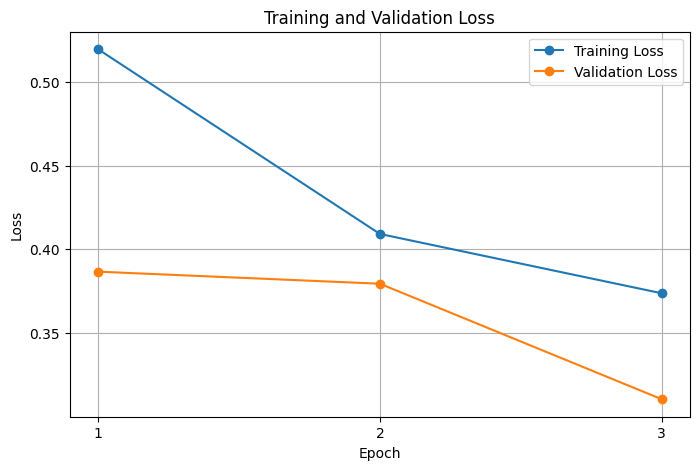

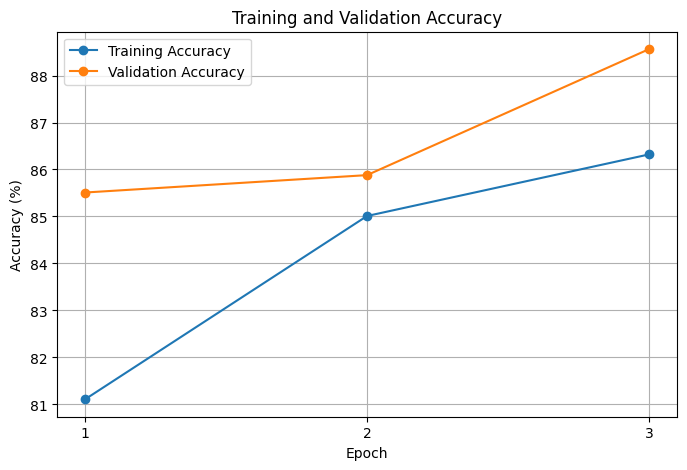

In [43]:
# Task 4 - Plot training and validation performance

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"],
         marker="o", label="Training Loss")

plt.plot(epochs, history["val_loss"],
         marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_accuracy"],
         marker="o", label="Training Accuracy")

plt.plot(epochs, history["val_accuracy"],
         marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Task 4 - Verify best model checkpoint

import torch
from pathlib import Path

checkpoint_path = Path("best_mobilenetv3.pth")

print("Checkpoint exists:", checkpoint_path.exists())

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

print("Saved epoch:", checkpoint["epoch"])
print("Saved validation loss:", checkpoint["val_loss"])
print("Saved image size:", checkpoint["image_size"])
print("Number of saved classes:", len(checkpoint["class_to_idx"]))

print(
    "Checkpoint matches best recorded loss:",
    abs(checkpoint["val_loss"] - min(history["val_loss"])) < 1e-8
)

Checkpoint exists: True
Saved epoch: 3
Saved validation loss: 0.3106449956587565
Saved image size: 128
Number of saved classes: 8
Checkpoint matches best recorded loss: True


# Task 5: Model Evaluation and Kaggle Submission

This task evaluates the saved MobileNetV3 Small model using the validation dataset. It calculates classification metrics, including accuracy, precision, recall, and F1-score, and generates a confusion matrix. The trained model is also used to predict the classes of the unlabelled Kaggle test images and prepare a submission file.

In [23]:
# Task 5 - Load the best trained model

import torch
from pathlib import Path

checkpoint_path = Path("best_mobilenetv3.pth")

# Check that the saved model exists
assert checkpoint_path.exists(), "Model checkpoint not found!"

# Load saved checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Restore trained weights
model.load_state_dict(checkpoint["model_state_dict"])

# Move model to device and enable evaluation mode
model = model.to(device)
model.eval()

# Verify saved configuration
assert checkpoint["class_to_idx"] == class_to_idx
assert checkpoint["image_size"] == IMAGE_SIZE

print("Best model loaded successfully")
print("Saved epoch:", checkpoint["epoch"])
print("Saved validation loss:", checkpoint["val_loss"])
print("Number of classes:", len(checkpoint["class_to_idx"]))
print("Device:", device)

Best model loaded successfully
Saved epoch: 3
Saved validation loss: 0.3106449956587565
Number of classes: 8
Device: cpu


In [24]:
# Task 5 - Calculate validation classification metrics

import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, targets in val_loader:

        images = images.to(device)

        # Generate predictions
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(targets.tolist())

# Calculate overall accuracy
accuracy = accuracy_score(all_labels, all_predictions)

print("Validation images evaluated:", len(all_labels))
print(f"Overall validation accuracy: {accuracy * 100:.2f}%")

# Display precision, recall and F1-score
print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

Validation images evaluated: 12732
Overall validation accuracy: 88.56%

Classification Report:
              precision    recall  f1-score   support

      CatEye     0.9451    0.9489    0.9470      2777
     CatFace     0.9795    0.9640    0.9717      1388
    CatMouth     0.8656    0.7471    0.8020      1388
     CatNose     0.7850    0.8567    0.8193      1389
      DogEye     0.8673    0.9313    0.8982      2316
     DogFace     0.9006    0.9387    0.9192      1158
    DogMouth     0.8226    0.8048    0.8136      1158
     DogNose     0.8679    0.7772    0.8200      1158

    accuracy                         0.8856     12732
   macro avg     0.8792    0.8711    0.8739     12732
weighted avg     0.8864    0.8856    0.8849     12732



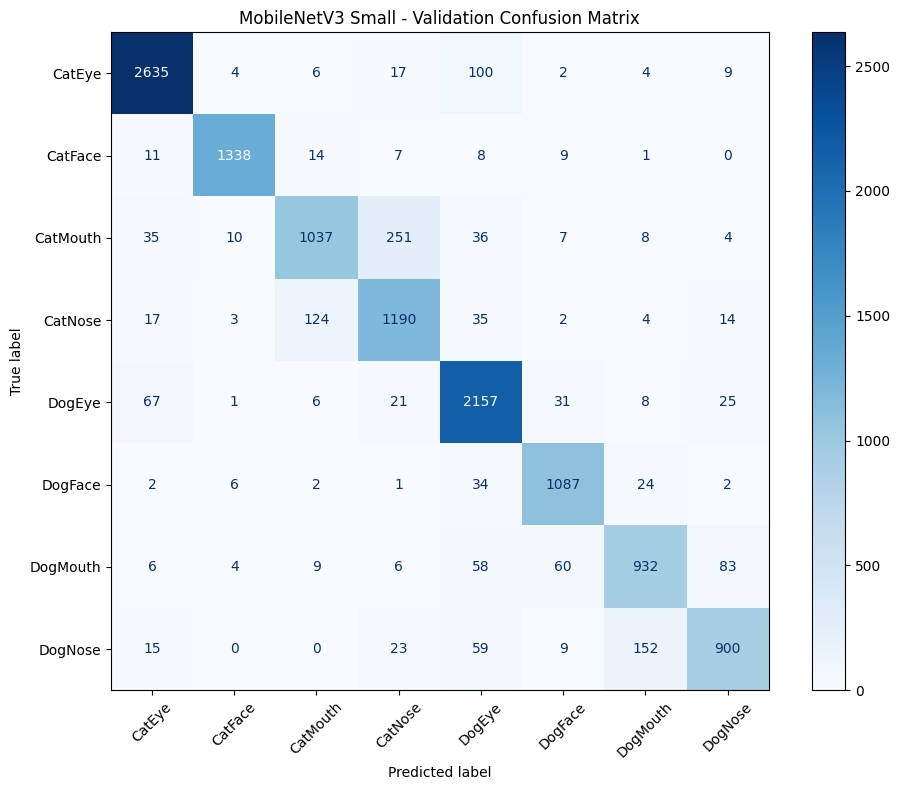

Total images in confusion matrix: 12732


In [25]:
# Task 5 - Generate confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

# Display confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=True
)

plt.title("MobileNetV3 Small - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print("Total images in confusion matrix:", cm.sum())

In [26]:
# Task 5 - Prepare Kaggle test dataset

import pandas as pd
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Load Kaggle submission template
submission = pd.read_csv("../sample_submission.csv")

test_folder = Path("../test/test")

class KaggleTestDataset(Dataset):
    def __init__(self, dataframe, image_folder, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_folder = Path(image_folder)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        image_id = str(
            self.dataframe.iloc[idx]["image_id"]
        ).zfill(5)

        image_path = self.image_folder / f"{image_id}.jpg"

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return image

# Create test dataset
test_dataset = KaggleTestDataset(
    submission,
    test_folder,
    val_transform
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Verify the test dataset
print("Submission rows:", len(submission))
print("Test dataset images:", len(test_dataset))
print("Test batches:", len(test_loader))

test_images = next(iter(test_loader))

print("Test batch shape:", test_images.shape)

Submission rows: 29443
Test dataset images: 29443
Test batches: 921
Test batch shape: torch.Size([32, 3, 128, 128])


In [27]:
# Task 5 - Generate predictions for Kaggle test images

import torch
import time

model.eval()

test_predictions = []
start_time = time.time()

with torch.no_grad():
    for batch_idx, images in enumerate(test_loader):

        images = images.to(device)

        # Generate model outputs
        outputs = model(images)

        # Select the class with the highest score
        predicted_indices = outputs.argmax(dim=1)

        # Convert numerical predictions to class names
        predicted_classes = [
            idx_to_class[int(idx)]
            for idx in predicted_indices.cpu().tolist()
        ]

        test_predictions.extend(predicted_classes)

        # Display progress every 100 batches
        if (batch_idx + 1) % 100 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(test_loader)} batches"
            )

print("\nPrediction completed!")
print("Total predictions:", len(test_predictions))
print("Expected predictions:", len(submission))
print("First 10 predictions:", test_predictions[:10])
print("Time taken:", round(time.time() - start_time, 2), "seconds")

# Verify prediction count and class names
assert len(test_predictions) == len(submission)
assert set(test_predictions).issubset(set(class_names))

print("Prediction checks passed!")

Processed 100/921 batches
Processed 200/921 batches
Processed 300/921 batches
Processed 400/921 batches
Processed 500/921 batches
Processed 600/921 batches
Processed 700/921 batches
Processed 800/921 batches
Processed 900/921 batches

Prediction completed!
Total predictions: 29443
Expected predictions: 29443
First 10 predictions: ['DogEye', 'DogMouth', 'DogNose', 'DogMouth', 'CatMouth', 'DogMouth', 'DogMouth', 'DogEye', 'CatEye', 'CatNose']
Time taken: 488.56 seconds
Prediction checks passed!


In [28]:
# Task 5 - Create Kaggle submission CSV

# Make a copy of the original submission template
final_submission = submission.copy()

# Insert model predictions
final_submission["class"] = test_predictions

# Save the CSV
final_submission.to_csv("submission.csv", index=False)

# Read it back to verify the saved file
saved_submission = pd.read_csv("submission.csv")

print("Submission file created successfully!")
print("File location:", Path("submission.csv").resolve())
print("Submission shape:", saved_submission.shape)
print("Columns:", saved_submission.columns.tolist())
print("Missing values:", saved_submission.isna().sum().sum())
print("Duplicate image IDs:", saved_submission["image_id"].duplicated().sum())

# Verify submission format and ordering
assert saved_submission.shape == (29443, 2)
assert saved_submission.columns.tolist() == ["image_id", "class"]
assert saved_submission["image_id"].equals(submission["image_id"])
assert saved_submission["class"].isin(class_names).all()
assert saved_submission.isna().sum().sum() == 0

print("\nFirst 5 rows:")
print(saved_submission.head())

print("\nAll submission checks passed!")

Submission file created successfully!
File location: C:\Users\simon\OneDrive - AUT University\Documents\Assignment3Ai\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\submission.csv
Submission shape: (29443, 2)
Columns: ['image_id', 'class']
Missing values: 0
Duplicate image IDs: 0

First 5 rows:
   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4  DogMouth
4         5  CatMouth

All submission checks passed!


In [29]:
from pathlib import Path

print("Submission file:", Path("submission.csv").resolve())
print("File exists:", Path("submission.csv").exists())

Submission file: C:\Users\simon\OneDrive - AUT University\Documents\Assignment3Ai\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\submission.csv
File exists: True


In [30]:
import os
from pathlib import Path

os.startfile(Path("submission.csv").resolve().parent)

# Task 6: Model Improvement and Comparison

This task implements and evaluates an additional model configuration for comparison with the baseline MobileNetV3 Small classifier. The experiment records validation performance and compares model configurations using consistent evaluation procedures.

In [31]:
# Task 6 - Save baseline model results

import pandas as pd
import torch
from pathlib import Path

baseline_results = {
    "model": "MobileNetV3 Small - Baseline",
    "epochs": len(history["train_loss"]),
    "train_accuracy": history["train_accuracy"][-1],
    "val_accuracy": history["val_accuracy"][-1],
    "train_loss": history["train_loss"][-1],
    "val_loss": history["val_loss"][-1],
    "kaggle_public_score": 0.8694
}

baseline_df = pd.DataFrame([baseline_results])

# Save baseline metrics separately
baseline_df.to_csv("baseline_results.csv", index=False)

# Verify the saved results
print("Baseline results:")
print(baseline_df.to_string(index=False))

print("\nBaseline file exists:",
      Path("baseline_results.csv").exists())

print("Best model checkpoint exists:",
      Path("best_mobilenetv3.pth").exists())

Baseline results:
                       model  epochs  train_accuracy  val_accuracy  train_loss  val_loss  kaggle_public_score
MobileNetV3 Small - Baseline       3       86.315975     88.564248    0.373834  0.310645               0.8694

Baseline file exists: True
Best model checkpoint exists: True


In [32]:
# Task 6 - Create a fine-tuning model

import torch
import torch.nn as nn
from torchvision import models

# Create a separate model
improved_model = models.mobilenet_v3_small(weights=None)

# Match the baseline's eight-class output
in_features = improved_model.classifier[3].in_features
improved_model.classifier[3] = nn.Linear(in_features, len(class_names))

# Load baseline weights
checkpoint = torch.load(
    "best_mobilenetv3.pth",
    map_location="cpu",
    weights_only=True
)

improved_model.load_state_dict(checkpoint["model_state_dict"])

# Freeze all feature extraction layers initially
for parameter in improved_model.features.parameters():
    parameter.requires_grad = False

# Unfreeze the final feature block
for parameter in improved_model.features[-1].parameters():
    parameter.requires_grad = True

# Keep classifier trainable
for parameter in improved_model.classifier.parameters():
    parameter.requires_grad = True

improved_model = improved_model.to(device)

# Use a smaller learning rate for fine-tuning
improved_optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, improved_model.parameters()),
    lr=0.0001
)

improved_criterion = nn.CrossEntropyLoss()

print("Fine-tuning model created")
print("Device:", device)
print("Learning rate:", improved_optimizer.param_groups[0]["lr"])

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in improved_model.parameters()
        if p.requires_grad
    )
)

print(
    "Frozen parameters:",
    sum(
        p.numel()
        for p in improved_model.parameters()
        if not p.requires_grad
    )
)

Fine-tuning model created
Device: cpu
Learning rate: 0.0001
Trainable parameters: 655496
Frozen parameters: 870560


In [ ]:
# Task 6 - Fine-tuning training and validation

import time
import torch
from pathlib import Path

FINE_TUNE_EPOCHS = 3

improved_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_improved_val_loss = float("inf")
improved_checkpoint_path = Path("best_mobilenetv3_finetuned.pth")
# Prevent accidentally overwriting the fine-tuned model
if improved_checkpoint_path.exists():
    raise FileExistsError(
        "The fine-tuned model already exists. Back it up before retraining."
    )

for epoch in range(FINE_TUNE_EPOCHS):

    start_time = time.time()

    # Training
    improved_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)

        improved_optimizer.zero_grad()

        outputs = improved_model(images)
        loss = improved_criterion(outputs, targets)

        loss.backward()
        improved_optimizer.step()

        train_loss_sum += loss.item() * targets.size(0)
        train_correct += (outputs.argmax(1) == targets).sum().item()
        train_total += targets.size(0)

    # Validation
    improved_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            outputs = improved_model(images)
            loss = improved_criterion(outputs, targets)

            val_loss_sum += loss.item() * targets.size(0)
            val_correct += (outputs.argmax(1) == targets).sum().item()
            val_total += targets.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = 100 * train_correct / train_total
    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    improved_history["train_loss"].append(train_loss)
    improved_history["train_accuracy"].append(train_accuracy)
    improved_history["val_loss"].append(val_loss)
    improved_history["val_accuracy"].append(val_accuracy)

    # Save best fine-tuned checkpoint
    if val_loss < best_improved_val_loss:
        best_improved_val_loss = val_loss

        torch.save({
            "model_state_dict": improved_model.state_dict(),
            "class_to_idx": class_to_idx,
            "image_size": IMAGE_SIZE,
            "epoch": epoch + 1,
            "val_loss": val_loss
        }, improved_checkpoint_path)

        print("Best fine-tuned checkpoint saved.")

    print(
        f"Epoch {epoch + 1}/{FINE_TUNE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Time: {time.time() - start_time:.1f}s",
        flush=True
    )

print("\nFine-tuning completed.")
print("Checkpoint:", improved_checkpoint_path.resolve())

Best fine-tuned checkpoint saved.
Epoch 1/3 | Train Loss: 0.2964 | Train Acc: 89.18% | Val Loss: 0.2566 | Val Acc: 90.78% | Time: 498.6s
Best fine-tuned checkpoint saved.
Epoch 2/3 | Train Loss: 0.2624 | Train Acc: 90.40% | Val Loss: 0.2400 | Val Acc: 91.35% | Time: 460.7s
Best fine-tuned checkpoint saved.
Epoch 3/3 | Train Loss: 0.2421 | Train Acc: 91.11% | Val Loss: 0.2292 | Val Acc: 91.60% | Time: 478.8s

Fine-tuning completed.
Checkpoint: C:\Users\simon\OneDrive - AUT University\Documents\Assignment3Ai\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\best_mobilenetv3_finetuned.pth


In [34]:
# Task 6 - Compare baseline and fine-tuned models

import pandas as pd

# Retrieve the best validation epoch for each model
baseline_best_idx = min(
    range(len(history["val_loss"])),
    key=lambda i: history["val_loss"][i]
)

improved_best_idx = min(
    range(len(improved_history["val_loss"])),
    key=lambda i: improved_history["val_loss"][i]
)

comparison_df = pd.DataFrame([
    {
        "Model": "Baseline MobileNetV3 Small",
        "Best Epoch": baseline_best_idx + 1,
        "Validation Loss": history["val_loss"][baseline_best_idx],
        "Validation Accuracy (%)": history["val_accuracy"][baseline_best_idx]
    },
    {
        "Model": "Fine-tuned MobileNetV3 Small",
        "Best Epoch": improved_best_idx + 1,
        "Validation Loss": improved_history["val_loss"][improved_best_idx],
        "Validation Accuracy (%)": improved_history["val_accuracy"][improved_best_idx]
    }
])

print(comparison_df.to_string(index=False))

# Save the comparison
comparison_df.to_csv("model_comparison.csv", index=False)

print("\nComparison file saved successfully!")

                       Model  Best Epoch  Validation Loss  Validation Accuracy (%)
  Baseline MobileNetV3 Small           3         0.310645                88.564248
Fine-tuned MobileNetV3 Small           3         0.229229                91.603833

Comparison file saved successfully!


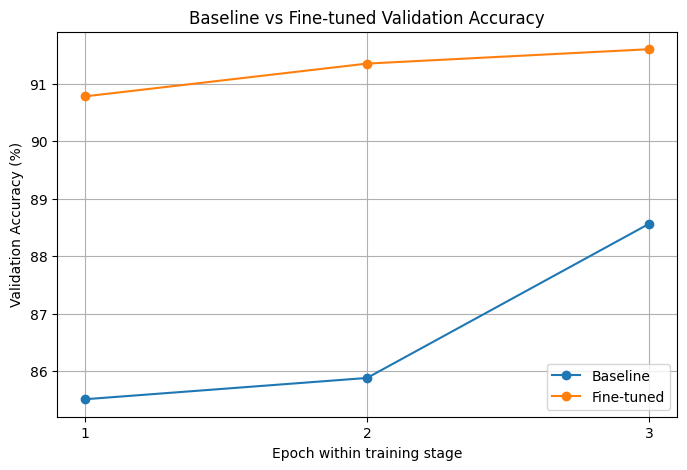

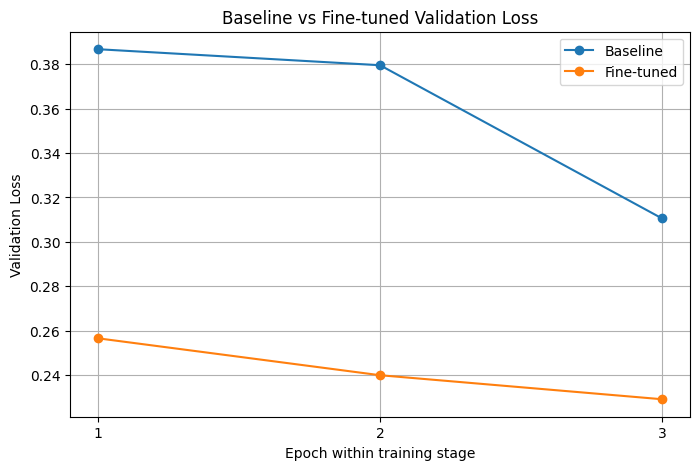

In [44]:
# Task 6 - Visualise baseline and fine-tuned model comparison

import matplotlib.pyplot as plt

epochs = range(1, len(history["val_loss"]) + 1)
fine_tune_epochs = range(1, len(improved_history["val_loss"]) + 1)

# Validation accuracy comparison
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Baseline"
)

plt.plot(
    fine_tune_epochs,
    improved_history["val_accuracy"],
    marker="o",
    label="Fine-tuned"
)

plt.xlabel("Epoch within training stage")
plt.ylabel("Validation Accuracy (%)")
plt.title("Baseline vs Fine-tuned Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()


# Validation loss comparison
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Baseline"
)

plt.plot(
    fine_tune_epochs,
    improved_history["val_loss"],
    marker="o",
    label="Fine-tuned"
)

plt.xlabel("Epoch within training stage")
plt.ylabel("Validation Loss")
plt.title("Baseline vs Fine-tuned Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()

In [36]:
# Task 6 - Load fine-tuned checkpoint and generate test predictions

import torch
import pandas as pd
import time
from pathlib import Path

# Load the best fine-tuned weights
fine_checkpoint = torch.load(
    "best_mobilenetv3_finetuned.pth",
    map_location=device,
    weights_only=True
)

improved_model.load_state_dict(
    fine_checkpoint["model_state_dict"]
)

improved_model = improved_model.to(device)
improved_model.eval()

# Verify class mapping
assert fine_checkpoint["class_to_idx"] == class_to_idx

fine_predictions = []
start_time = time.time()

with torch.no_grad():
    for batch_idx, images in enumerate(test_loader):

        images = images.to(device)

        outputs = improved_model(images)
        predicted_indices = outputs.argmax(dim=1)

        fine_predictions.extend([
            idx_to_class[int(idx)]
            for idx in predicted_indices.cpu().tolist()
        ])

        if (batch_idx + 1) % 100 == 0:
            print(f"Processed {batch_idx + 1}/{len(test_loader)} batches")

print("\nPredictions generated:", len(fine_predictions))
print("Time taken:", round(time.time() - start_time, 2), "seconds")

assert len(fine_predictions) == len(submission)
assert set(fine_predictions).issubset(set(class_names))

print("Fine-tuned prediction checks passed!")

Processed 100/921 batches
Processed 200/921 batches
Processed 300/921 batches
Processed 400/921 batches
Processed 500/921 batches
Processed 600/921 batches
Processed 700/921 batches
Processed 800/921 batches
Processed 900/921 batches

Predictions generated: 29443
Time taken: 175.67 seconds
Fine-tuned prediction checks passed!


In [37]:
# Task 6 - Create fine-tuned Kaggle submission

from pathlib import Path
import pandas as pd

# Copy original Kaggle submission template
fine_submission = submission.copy()

# Add fine-tuned model predictions
fine_submission["class"] = fine_predictions

# Save as a separate CSV
fine_submission.to_csv(
    "submission_finetuned.csv",
    index=False
)

# Read saved file to verify
saved_fine_submission = pd.read_csv(
    "submission_finetuned.csv"
)

print("File location:",
      Path("submission_finetuned.csv").resolve())

print("Submission shape:", saved_fine_submission.shape)
print("Columns:", saved_fine_submission.columns.tolist())
print("Missing values:", saved_fine_submission.isna().sum().sum())
print("Duplicate image IDs:",
      saved_fine_submission["image_id"].duplicated().sum())

# Verify submission
assert saved_fine_submission.shape == (29443, 2)
assert saved_fine_submission.columns.tolist() == ["image_id", "class"]
assert saved_fine_submission["image_id"].equals(submission["image_id"])
assert saved_fine_submission["class"].isin(class_names).all()
assert saved_fine_submission.isna().sum().sum() == 0

print("\nFirst 5 rows:")
print(saved_fine_submission.head())

print("\nAll fine-tuned submission checks passed!")

File location: C:\Users\simon\OneDrive - AUT University\Documents\Assignment3Ai\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\submission_finetuned.csv
Submission shape: (29443, 2)
Columns: ['image_id', 'class']
Missing values: 0
Duplicate image IDs: 0

First 5 rows:
   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4  DogMouth
4         5  CatMouth

All fine-tuned submission checks passed!


In [38]:
# Task 6 - Record Kaggle public leaderboard results

kaggle_results = pd.DataFrame({
    "Model": [
        "Baseline MobileNetV3 Small",
        "Fine-tuned MobileNetV3 Small"
    ],
    "Public Score": [0.8694, 0.9003]
})

kaggle_results["Score Difference"] = (
    kaggle_results["Public Score"] - 0.8694
)

print(kaggle_results.to_string(index=False))

kaggle_results.to_csv("kaggle_results.csv", index=False)

print("\nKaggle results saved successfully!")

                       Model  Public Score  Score Difference
  Baseline MobileNetV3 Small        0.8694            0.0000
Fine-tuned MobileNetV3 Small        0.9003            0.0309

Kaggle results saved successfully!


In [39]:
# Final project verification

from pathlib import Path

required_files = [
    "best_mobilenetv3.pth",
    "best_mobilenetv3_finetuned.pth",
    "submission.csv",
    "submission_finetuned.csv",
    "baseline_results.csv",
    "model_comparison.csv",
    "kaggle_results.csv"
]

print("PROJECT FILE CHECK\n")

for filename in required_files:
    exists = Path(filename).exists()
    print(f"{filename}: {'FOUND' if exists else 'MISSING'}")

print("\nDATASET CHECK")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_dataset))

print("\nMODEL CHECK")
print("Classes:", len(class_names))
print("Baseline best validation accuracy:",
      round(max(history["val_accuracy"]), 2), "%")
print("Fine-tuned best validation accuracy:",
      round(max(improved_history["val_accuracy"]), 2), "%")

print("\nKAGGLE PUBLIC SCORES")
print("Baseline:", 0.8694)
print("Fine-tuned:", 0.9003)

print("\nAll required files present:",
      all(Path(f).exists() for f in required_files))

PROJECT FILE CHECK

best_mobilenetv3.pth: FOUND
best_mobilenetv3_finetuned.pth: FOUND
submission.csv: FOUND
submission_finetuned.csv: FOUND
baseline_results.csv: FOUND
model_comparison.csv: FOUND
kaggle_results.csv: FOUND

DATASET CHECK
Training images: 50928
Validation images: 12732
Test images: 29443

MODEL CHECK
Classes: 8
Baseline best validation accuracy: 88.56 %
Fine-tuned best validation accuracy: 91.6 %

KAGGLE PUBLIC SCORES
Baseline: 0.8694
Fine-tuned: 0.9003

All required files present: True


In [39]:
import json

with open("Assessment3.ipynb", "r", encoding="utf-8") as f:
    notebook = json.load(f)

for cell in notebook["cells"]:
    for output in cell.get("outputs", []):
        for line in output.get("text", []):
            if line.startswith("Epoch "):
                print(line.strip())

Epoch 1/3 | Train Loss: 0.5194 | Train Acc: 81.11% | Val Loss: 0.3867 | Val Acc: 85.51% | Time: 542.6s
Epoch 2/3 | Train Loss: 0.4092 | Train Acc: 85.01% | Val Loss: 0.3795 | Val Acc: 85.88% | Time: 467.4s
Epoch 3/3 | Train Loss: 0.3738 | Train Acc: 86.32% | Val Loss: 0.3106 | Val Acc: 88.56% | Time: 460.1s
Epoch 1/3 | Train Loss: 0.2964 | Train Acc: 89.18% | Val Loss: 0.2566 | Val Acc: 90.78% | Time: 498.6s
Epoch 2/3 | Train Loss: 0.2624 | Train Acc: 90.40% | Val Loss: 0.2400 | Val Acc: 91.35% | Time: 460.7s
Epoch 3/3 | Train Loss: 0.2421 | Train Acc: 91.11% | Val Loss: 0.2292 | Val Acc: 91.60% | Time: 478.8s


In [40]:
import re
import pandas as pd

pattern = re.compile(
    r"Epoch (\d+)/\d+ \| "
    r"Train Loss: ([\d.]+) \| "
    r"Train Acc: ([\d.]+)% \| "
    r"Val Loss: ([\d.]+) \| "
    r"Val Acc: ([\d.]+)%"
)

rows = []

for cell in notebook["cells"]:
    for output in cell.get("outputs", []):
        for line in output.get("text", []):
            match = pattern.search(line)

            if match:
                epoch, train_loss, train_acc, val_loss, val_acc = match.groups()
                rows.append({
                    "epoch": int(epoch),
                    "train_loss": float(train_loss),
                    "train_accuracy": float(train_acc),
                    "val_loss": float(val_loss),
                    "val_accuracy": float(val_acc)
                })

if len(rows) != 6:
    raise ValueError(f"Expected 6 epoch results, found {len(rows)}")

pd.DataFrame(rows[:3]).to_csv("baseline_history_recovered.csv", index=False)
pd.DataFrame(rows[3:]).to_csv("finetuned_history_recovered.csv", index=False)

print("Baseline epochs saved:", len(rows[:3]))
print("Fine-tuned epochs saved:", len(rows[3:]))
print("Both history files saved successfully!")

Baseline epochs saved: 3
Fine-tuned epochs saved: 3
Both history files saved successfully!


In [41]:
import pandas as pd

baseline = pd.read_csv("baseline_history_recovered.csv")
finetuned = pd.read_csv("finetuned_history_recovered.csv")

print("Baseline history:")
print(baseline)

print("\nFine-tuned history:")
print(finetuned)

Baseline history:
   epoch  train_loss  train_accuracy  val_loss  val_accuracy
0      1      0.5194           81.11    0.3867         85.51
1      2      0.4092           85.01    0.3795         85.88
2      3      0.3738           86.32    0.3106         88.56

Fine-tuned history:
   epoch  train_loss  train_accuracy  val_loss  val_accuracy
0      1      0.2964           89.18    0.2566         90.78
1      2      0.2624           90.40    0.2400         91.35
2      3      0.2421           91.11    0.2292         91.60


In [42]:
import pandas as pd

# Load previously recovered training histories
baseline_df = pd.read_csv("baseline_history_recovered.csv")
finetuned_df = pd.read_csv("finetuned_history_recovered.csv")

metrics = ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]

history = {
    metric: baseline_df[metric].tolist()
    for metric in metrics
}

improved_history = {
    metric: finetuned_df[metric].tolist()
    for metric in metrics
}

print("Baseline epochs restored:", len(history["train_loss"]))
print("Fine-tuned epochs restored:", len(improved_history["train_loss"]))

Baseline epochs restored: 3
Fine-tuned epochs restored: 3
